# Segmentación de inmuebles en arriendo con K-Means
**Universidad de Cundinamarca – Esp. Inteligencia Artificial – Introducción a Machine Learning (2026-2)**  
**Estudiante:** Laura Fernanda López Mayorga  

Versión adaptada del ejemplo `KMeansSegInmuebles.py` para leer el dataset entregado (`DATASET_INmuebles.xlsx`) y evaluar K-Means con k = 2, 3 y 4.

## 1. Librerías y carga de datos

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
warnings.filterwarnings("ignore")
os.makedirs("figuras", exist_ok=True)
plt.rcParams["figure.dpi"] = 110

RUTA = "DATASET_INmuebles.xlsx"
# En Google Colab: si el archivo no está en el entorno, se solicita subirlo.
if not os.path.exists(RUTA):
    try:
        from google.colab import files
        files.upload()
    except ImportError:
        raise FileNotFoundError("Coloque DATASET_INmuebles.xlsx junto al notebook.")

In [2]:
df_raw = pd.read_excel(RUTA)
print("Dimensiones originales:", df_raw.shape)
print("Columnas originales:", list(df_raw.columns))
df_raw.head()

Dimensiones originales: (1000, 10)
Columnas originales: ['Inmueble', 'Área m²', 'Habitaciones', 'Estrato', 'Precio arriendo', 'Baños', 'Antig[uedad', 'Localidad', 'Tipo Inmueble', 'Estrato.1']


,Inmueble,Área m²,Habitaciones,Estrato,Precio arriendo,Baños,Antig[uedad,Localidad,Tipo Inmueble,Estrato.1
0,I1,69,2,2,1413951,2,11,Suba,Apto,2
1,I2,39,1,2,1006165,2,10,Chapinero,Casa,3
2,I3,142,5,5,8570904,1,8,Usaquén,ApartaEstudio,4
3,I4,62,3,4,3678698,1,12,Suba,Apto,3
4,I5,58,1,3,875729,1,12,Chapinero,Casa,4


## 2. Calidad de datos

In [3]:
# Normalización de nombres de columnas (el archivo trae 'Antig[uedad' y un segundo 'Estrato')
df = df_raw.rename(columns={
    "Inmueble": "Id_inmueble", "Área m²": "Area_m2", "Precio arriendo": "Precio_arriendo",
    "Baños": "Banos", "Antig[uedad": "Antiguedad_anios", "Tipo Inmueble": "Tipo_inmueble",
    "Estrato.1": "Estrato_dup"})

print("Valores nulos:", int(df.isna().sum().sum()))
print("Registros duplicados (sin Id):", int(df.drop(columns="Id_inmueble").duplicated().sum()))
print("Correlación Estrato vs Estrato_dup:", round(df["Estrato"].corr(df["Estrato_dup"]), 3))
print("Coincidencia exacta entre ambos estratos:", f'{(df["Estrato"] == df["Estrato_dup"]).mean():.1%}')
print("\nRelación Localidad vs Tipo_inmueble:")
print(pd.crosstab(df["Localidad"], df["Tipo_inmueble"]))

Valores nulos: 0
Registros duplicados (sin Id): 0
Correlación Estrato vs Estrato_dup: 0.041
Coincidencia exacta entre ambos estratos: 16.7%

Relación Localidad vs Tipo_inmueble:
Tipo_inmueble  ApartaEstudio  Apto  Casa
Localidad                               
Chapinero                  0     0   333
Suba                       0   334     0
Usaquén                  333     0     0


**Decisiones de preprocesamiento**

* `Id_inmueble` se conserva para identificar registros, pero **no** se usa en el cálculo de distancias (requisito del enunciado).
* El archivo trae dos columnas de estrato. `Estrato` (rango 2–6) está fuertemente correlacionada con precio y área, mientras `Estrato_dup` (rango 1–4) coincide solo en ~17 % de los casos y su correlación con `Estrato` es ≈ 0.04, por lo que se trata como una columna inconsistente y se excluye.
* `Localidad` y `Tipo_inmueble` son redundantes: cada localidad tiene un único tipo (Chapinero → Casa, Suba → Apto, Usaquén → ApartaEstudio). Codificar ambas duplicaría el peso de la ubicación, por eso solo se codifica `Localidad` con One-Hot.
* Las variables numéricas se estandarizan (media 0, desviación 1) porque K-Means y PCA son sensibles a la escala; sin esto el precio (millones de pesos) dominaría todas las distancias.

## 3. Análisis exploratorio

In [4]:
df[["Precio_arriendo", "Area_m2", "Habitaciones", "Banos", "Antiguedad_anios", "Estrato"]].describe().round(2)

,Precio_arriendo,Area_m2,Habitaciones,Banos,Antiguedad_anios,Estrato
count,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00
mean,3633286.68,96.73,2.66,1.48,8.46,3.96
std,2438534.26,54.10,1.28,0.50,2.35,1.43
min,702480.00,30.00,1.00,1.00,5.00,2.00
25%,1644060.25,55.00,2.00,1.00,6.00,3.00
50%,2930804.50,80.50,2.00,1.00,8.50,4.00
75%,5394807.00,135.00,4.00,2.00,10.00,5.00
max,8988836.00,220.00,5.00,2.00,12.00,6.00


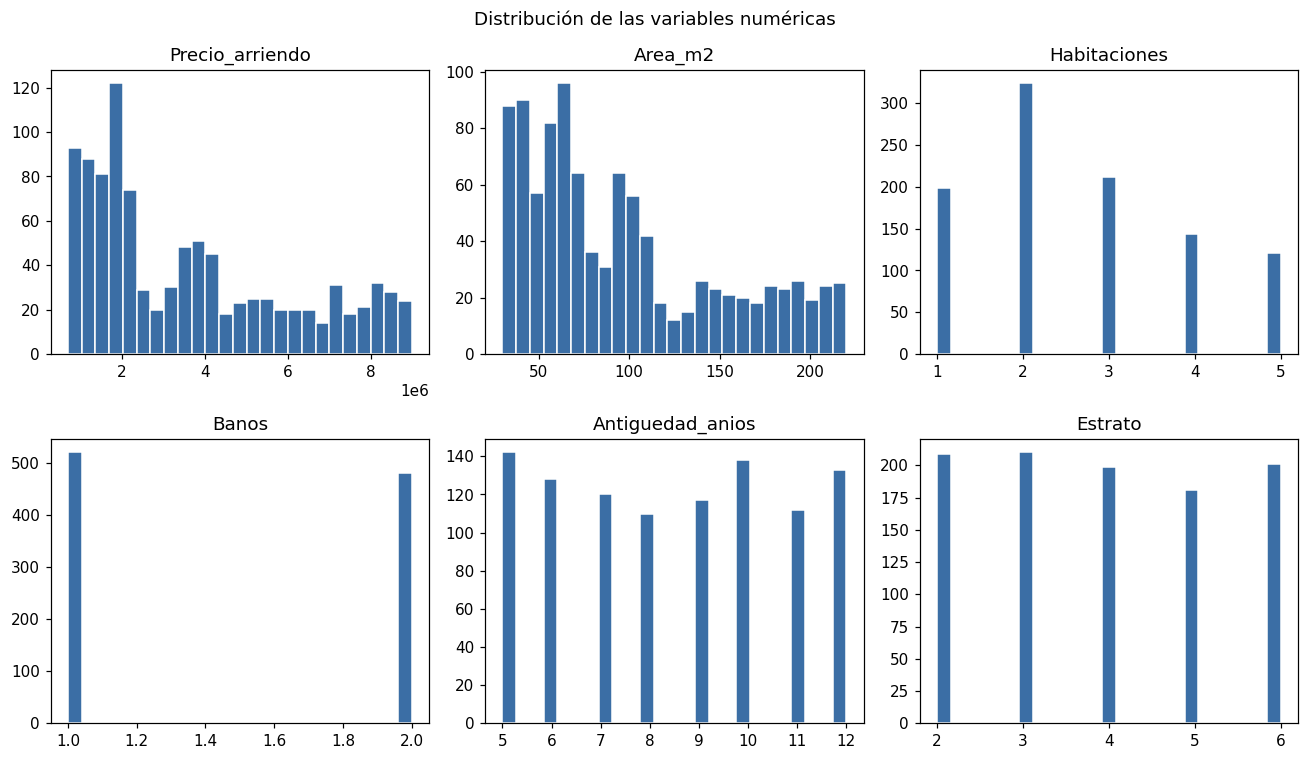

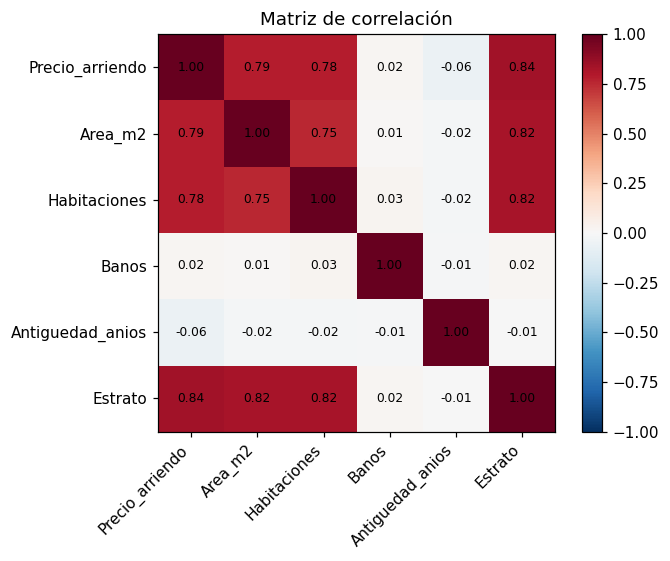

In [5]:
cols = ["Precio_arriendo", "Area_m2", "Habitaciones", "Banos", "Antiguedad_anios", "Estrato"]
fig, ax = plt.subplots(2, 3, figsize=(12, 7))
for a, c in zip(ax.ravel(), cols):
    a.hist(df[c], bins=25, color="#3b6ea5", edgecolor="white"); a.set_title(c)
plt.suptitle("Distribución de las variables numéricas"); plt.tight_layout()
plt.savefig("figuras/f1_histogramas.png", dpi=150); plt.show()

C = df[cols].corr()
fig, a = plt.subplots(figsize=(6.5, 5.2))
im = a.imshow(C, cmap="RdBu_r", vmin=-1, vmax=1)
a.set_xticks(range(len(cols))); a.set_xticklabels(cols, rotation=45, ha="right")
a.set_yticks(range(len(cols))); a.set_yticklabels(cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        a.text(j, i, f"{C.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im); plt.title("Matriz de correlación"); plt.tight_layout()
plt.savefig("figuras/f2_correlacion.png", dpi=150); plt.show()

In [6]:
# Cruce Estrato vs Habitaciones y rangos de precio por estrato
print(pd.crosstab(df["Estrato"], df["Habitaciones"]))
df.groupby("Estrato")[["Precio_arriendo", "Area_m2"]].agg(["min", "mean", "max"]).round(0)

Habitaciones    1    2   3   4   5
Estrato                           
2              97  112   0   0   0
3             102  108   0   0   0
4               0  104  95   0   0
5               0    0  57  68  56
6               0    0  60  76  65


Precio_arriendo                     Area_m2            
                    min       mean      max     min   mean  max
Estrato                                                        
2                702480  1446739.0  2192692      30   50.0   70
3                712144  1491558.0  2192854      30   49.0   70
4               1800798  3069443.0  4166099      60   85.0  110
5               3533583  6352920.0  8979727      90  154.0  220
6               3524810  6253698.0  8988836      90  155.0  220

## 4. Preprocesamiento

In [7]:
NUM = ["Precio_arriendo", "Area_m2", "Habitaciones", "Banos", "Antiguedad_anios", "Estrato"]
CAT = ["Localidad"]

preprocesador = ColumnTransformer([
    ("num", StandardScaler(), NUM),
    ("cat", OneHotEncoder(sparse_output=False), CAT)])
X = preprocesador.fit_transform(df)
nombres = [n.replace("num__", "").replace("cat__", "") for n in preprocesador.get_feature_names_out()]
print("Matriz para el modelo:", X.shape)
print(nombres)

def ordenar_por_precio(etiquetas):
    """Renumera los clústeres de menor a mayor precio medio para que la lectura sea estable."""
    orden = df.groupby(etiquetas)["Precio_arriendo"].mean().sort_values().index
    mapa = {viejo: nuevo for nuevo, viejo in enumerate(orden)}
    return np.array([mapa[e] for e in etiquetas])

def perfil(etiquetas):
    g = df.assign(Cluster=etiquetas).groupby("Cluster")
    p = g[NUM].mean().round(2)
    p["Precio_arriendo"] = p["Precio_arriendo"].round(0)
    p["N_inmuebles"] = g.size()
    return p

Matriz para el modelo: (1000, 9)
['Precio_arriendo', 'Area_m2', 'Habitaciones', 'Banos', 'Antiguedad_anios', 'Estrato', 'Localidad_Chapinero', 'Localidad_Suba', 'Localidad_Usaquén']


## 5. Selección del número de clústeres (codo, silueta, Davies-Bouldin, Calinski-Harabasz)

,k,Inercia,Silueta,Davies_Bouldin,Calinski_Harabasz
0,2,3777.760,0.380,1.112,763.185
1,3,3160.355,0.289,1.368,553.070
2,4,2776.902,0.257,1.657,465.051
3,5,2528.012,0.235,1.567,407.233
4,6,2314.429,0.239,1.599,373.839
5,7,2154.825,0.228,1.565,346.529
6,8,1997.647,0.233,1.592,331.223


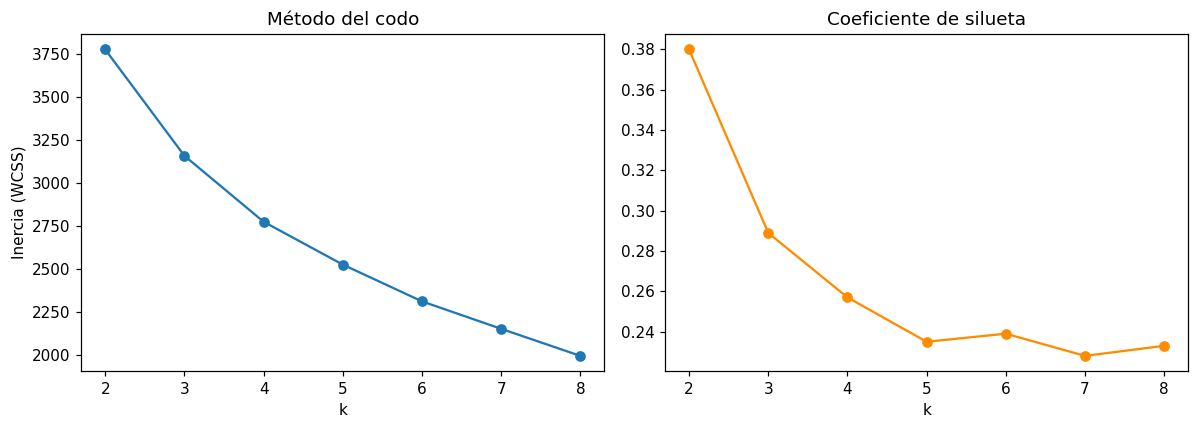

In [8]:
filas = []
for k in range(2, 9):
    m = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
    filas.append({"k": k, "Inercia": m.inertia_,
                  "Silueta": silhouette_score(X, m.labels_),
                  "Davies_Bouldin": davies_bouldin_score(X, m.labels_),
                  "Calinski_Harabasz": calinski_harabasz_score(X, m.labels_)})
metricas = pd.DataFrame(filas).round(3)
display(metricas)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(metricas["k"], metricas["Inercia"], "o-"); ax[0].set_title("Método del codo")
ax[0].set_xlabel("k"); ax[0].set_ylabel("Inercia (WCSS)")
ax[1].plot(metricas["k"], metricas["Silueta"], "o-", color="darkorange"); ax[1].set_title("Coeficiente de silueta")
ax[1].set_xlabel("k"); plt.tight_layout(); plt.savefig("figuras/f3_codo_silueta.png", dpi=150); plt.show()

## 6. Modelo base del ejemplo: k = 3

In [9]:
modelo = KMeans(n_clusters=3, random_state=42, n_init=10)
df["Cluster_k3"] = ordenar_por_precio(modelo.fit_predict(X))
print("Silueta k=3:", round(silhouette_score(X, df["Cluster_k3"]), 3))
perfil(df["Cluster_k3"])

Silueta k=3: 0.289


,Precio_arriendo,Area_m2,Habitaciones,Banos,Antiguedad_anios,Estrato,N_inmuebles
Cluster,,,,,,,
0,1967061.0,60.68,1.83,2.00,8.48,2.98,292
1,2000101.0,61.25,1.83,1.00,8.56,2.99,326
2,6300712.0,154.56,4.01,1.49,8.35,5.53,382


In [10]:
pd.crosstab(df["Cluster_k3"], df["Localidad"], normalize="index").mul(100).round(1)

Localidad,Chapinero,Suba,Usaquén
Cluster_k3,,,
0,36.0,34.6,29.5
1,34.4,35.0,30.7
2,30.4,31.2,38.5


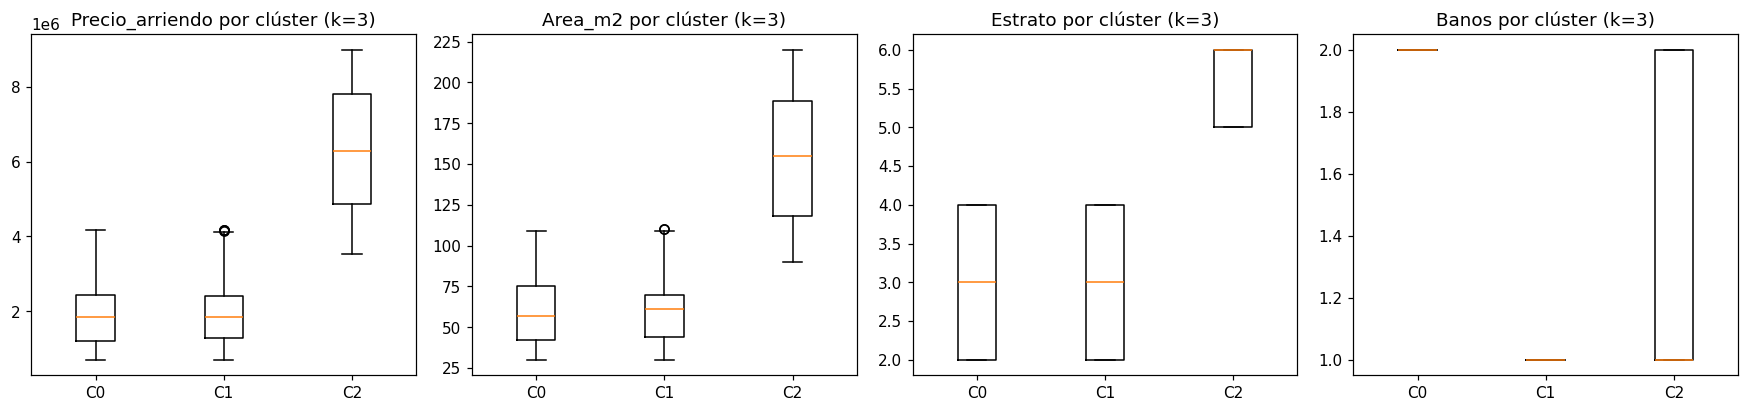

In [11]:
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for a, c in zip(ax, ["Precio_arriendo", "Area_m2", "Estrato", "Banos"]):
    a.boxplot([df.loc[df["Cluster_k3"] == i, c] for i in range(3)], tick_labels=["C0", "C1", "C2"])
    a.set_title(f"{c} por clúster (k=3)")
plt.tight_layout(); plt.savefig("figuras/f7_boxplots_k3.png", dpi=150); plt.show()

## 7. Actividad 3a: `KMeans(n_clusters=2, random_state=42, n_init=10)`

In [12]:
modelo = KMeans(n_clusters=2, random_state=42, n_init=10)
df["Cluster_k2"] = ordenar_por_precio(modelo.fit_predict(X))
print("Silueta k=2:", round(silhouette_score(X, df["Cluster_k2"]), 3))
perfil(df["Cluster_k2"])

Silueta k=2: 0.38


,Precio_arriendo,Area_m2,Habitaciones,Banos,Antiguedad_anios,Estrato,N_inmuebles
Cluster,,,,,,,
0,1984490.0,60.98,1.83,1.47,8.52,2.98,618
1,6300712.0,154.56,4.01,1.49,8.35,5.53,382


## 8. Actividad 3b: `KMeans(n_clusters=4, random_state=42, n_init=10)`

In [13]:
modelo = KMeans(n_clusters=4, random_state=42, n_init=10)
df["Cluster_k4"] = ordenar_por_precio(modelo.fit_predict(X))
print("Silueta k=4:", round(silhouette_score(X, df["Cluster_k4"]), 3))
perfil(df["Cluster_k4"])

Silueta k=4: 0.257


,Precio_arriendo,Area_m2,Habitaciones,Banos,Antiguedad_anios,Estrato,N_inmuebles
Cluster,,,,,,,
0,1967061.0,60.68,1.83,2.0,8.48,2.98,292
1,2000101.0,61.25,1.83,1.0,8.56,2.99,326
2,6275222.0,154.76,3.96,1.0,8.34,5.52,194
3,6327014.0,154.35,4.06,2.0,8.37,5.54,188


## 9. Escenario refinado: solo variables con estructura (precio, área, habitaciones, estrato)
`Banos` y `Antiguedad_anios` no se correlacionan con ninguna otra variable (|r| < 0.06) y `Banos` es binaria (1 ó 2); al estandarizarse, esa separación binaria atrae a K-Means. Se repite el análisis sin ellas y sin la localidad para verificar si aparecen los segmentos comerciales esperados.

In [14]:
NUCLEO = ["Precio_arriendo", "Area_m2", "Habitaciones", "Estrato"]
X_nucleo = StandardScaler().fit_transform(df[NUCLEO])
for k in [2, 3, 4]:
    m = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_nucleo)
    print(f"k={k}  silueta={silhouette_score(X_nucleo, m.labels_):.3f}")
modelo_ref = KMeans(n_clusters=3, random_state=42, n_init=10)
df["Segmento"] = ordenar_por_precio(modelo_ref.fit_predict(X_nucleo))
df["Segmento_nombre"] = df["Segmento"].map({0: "Económico", 1: "Intermedio", 2: "Premium"})
p = perfil(df["Segmento"]); p.index = ["Económico", "Intermedio", "Premium"]; p

k=2  silueta=0.611
k=3  silueta=0.482
k=4  silueta=0.427


,Precio_arriendo,Area_m2,Habitaciones,Banos,Antiguedad_anios,Estrato,N_inmuebles
Económico,1469202.0,49.66,1.53,1.47,8.51,2.50,419
Intermedio,3130625.0,85.36,2.52,1.47,8.58,4.06,209
Premium,6353200.0,156.13,4.03,1.50,8.33,5.53,372


In [15]:
pd.crosstab(df["Segmento_nombre"], df["Localidad"], normalize="index").mul(100).round(1)

Localidad,Chapinero,Suba,Usaquén
Segmento_nombre,,,
Económico,34.8,36.3,28.9
Intermedio,34.4,31.6,34.0
Premium,30.9,31.2,37.9


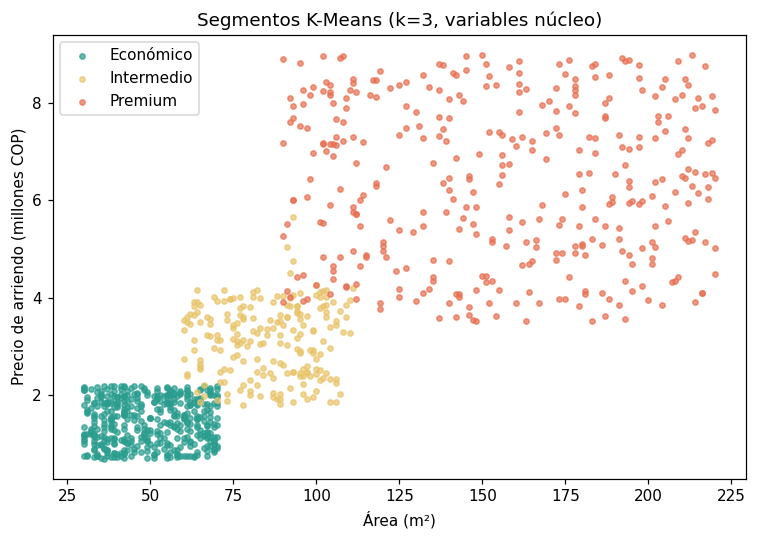

In [16]:
fig, a = plt.subplots(figsize=(7, 5))
colores = {"Económico": "#2a9d8f", "Intermedio": "#e9c46a", "Premium": "#e76f51"}
for s, c in colores.items():
    d = df[df["Segmento_nombre"] == s]
    a.scatter(d["Area_m2"], d["Precio_arriendo"] / 1e6, s=12, alpha=.7, color=c, label=s)
a.set_xlabel("Área (m²)"); a.set_ylabel("Precio de arriendo (millones COP)")
a.set_title("Segmentos K-Means (k=3, variables núcleo)"); a.legend()
plt.tight_layout(); plt.savefig("figuras/f12_segmentos_refinados.png", dpi=150); plt.show()

## 10. Exportar resultados (se conserva el identificador)

In [17]:
salida = df[["Id_inmueble", "Localidad", "Tipo_inmueble", "Precio_arriendo", "Area_m2",
             "Habitaciones", "Banos", "Estrato", "Cluster_k2", "Cluster_k3", "Cluster_k4", "Segmento_nombre"]]
salida.to_csv("inmuebles_segmentados.csv", index=False, encoding="utf-8-sig")
salida.head(10)

,Id_inmueble,Localidad,Tipo_inmueble,Precio_arriendo,Area_m2,Habitaciones,Banos,Estrato,Cluster_k2,Cluster_k3,Cluster_k4,Segmento_nombre
0,I1,Suba,Apto,1413951,69,2,2,2,0,0,0,Económico
1,I2,Chapinero,Casa,1006165,39,1,2,2,0,0,0,Económico
2,I3,Usaquén,ApartaEstudio,8570904,142,5,1,5,1,2,2,Premium
3,I4,Suba,Apto,3678698,62,3,1,4,0,1,1,Intermedio
4,I5,Chapinero,Casa,875729,58,1,1,3,0,1,1,Económico
5,I6,Usaquén,ApartaEstudio,2836207,76,3,1,4,0,1,1,Intermedio
6,I7,Suba,Apto,3808969,80,2,2,4,0,0,0,Intermedio
7,I8,Chapinero,Casa,8338969,204,4,1,6,1,2,2,Premium
8,I9,Usaquén,ApartaEstudio,8336930,99,4,2,5,1,2,3,Premium
9,I10,Suba,Apto,5758932,111,5,1,5,1,2,2,Premium
